# Audience Sensitivity, Content Compliance & Format Preference Analysis of France Top 50 Playlist

**Client:** Atlantic Recording Corporation  |  **Data:** `Atlantic_France.csv` (daily France Top 50 playlist snapshots)

## 1. Introduction
Atlantic Recording Corporation wants to understand how music content and release structure perform in the French market. This notebook answers six business questions:

1. How does explicit content perform compared with clean content?
2. Does the France Top 50 favour Singles or Album tracks?
3. What song-duration range is most common among stronger-performing tracks?
4. Does album size influence track popularity or rank?
5. Which content characteristics are more concentrated in the Top 10?
6. What content profile appears most accepted in the France Top 50?

**How to read it:** every section follows *explanation -> code -> result -> interpretation*. The workflow is Inspect -> Validate -> Clean -> Engineer features -> EDA -> Analyse -> KPIs -> Statistical tests -> Findings.

**Ground rules:** the raw file is never changed; results are never assumed; rank and popularity are **not** streaming volumes; correlation is not causation.

## 2. Imports
Libraries, project paths and chart styling. The colour of each category (Explicit, Clean, Single, Album) is fixed so it means the same thing in every chart.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# Find the project folder whether Jupyter is started in /notebooks or in the project root
PROJECT_DIR = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))

import data_processing as dp      # loading, cleaning, feature engineering
import analysis_utils as au       # profiles, KPIs, statistical tests

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# One fixed colour per category
COLORS = {"Explicit": "#eb6834", "Clean": "#2a78d6", "Single": "#1baf7a", "Album": "#6250d6"}
TEXT_ON = {"Explicit": "#0b0b0b", "Clean": "white", "Single": "#0b0b0b", "Album": "white"}
SEQ = ["#a9c9f0", "#5a9be0", "#1f5fae"]          # ordered groups (small -> large, short -> long)
GREY = "#b8bcc4"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
                     "grid.color": "#e6e6e3"})

os.makedirs(dp.FIGURES_DIR, exist_ok=True)
os.makedirs(dp.TABLES_DIR, exist_ok=True)

def save_table(table, name):
    """Save an analysis table to outputs/tables."""
    table.to_csv(os.path.join(dp.TABLES_DIR, name + ".csv"), index=False)

def save_fig(fig, name):
    """Save a figure to outputs/figures and show it."""
    fig.savefig(os.path.join(dp.FIGURES_DIR, name + ".png"), dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

## 3. Dataset Loading
The file is read with **every column as text** so nothing is silently converted - the validation step can then see the real raw values. The raw file stays untouched in `data/raw/`.

In [2]:
raw = dp.load_raw()
print("File used     :", os.path.basename(dp.RAW_PATH))
print("Shape         :", raw.shape, "(rows, columns)")
raw.head()

File used     : Atlantic_France.csv
Shape         : (27800, 10) (rows, columns)


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,LA RUE,No Limit & Gazo & Damso,72,225137,single,1,TRUE,https://i.scdn.co/image/ab67616d0000b27384f2454da0973c07a508b57e
1,18-05-2024,2,C'est carré le S,Naps,74,201533,album,22,FALSE,https://i.scdn.co/image/ab67616d0000b27348f7c15d2c4dde71d11262e6
2,18-05-2024,3,Freestyle LVL UP 1,Ninho,76,114182,single,1,TRUE,https://i.scdn.co/image/ab67616d0000b273fbe613b1c15b681dc3e84dfe
3,18-05-2024,4,Bolide allemand,SDM,79,176746,album,15,TRUE,https://i.scdn.co/image/ab67616d0000b273455e89dbf3ce2e6d337be1d0
4,18-05-2024,5,Freestyle LVL UP 2,Ninho,71,149064,single,1,TRUE,https://i.scdn.co/image/ab67616d0000b27351f1cbc3fed8aeb3583ae1ee


**Result / interpretation.** The file is `Atlantic_France.csv` with **27,800 rows and 10 columns**, exactly the expected fields (`date, position, song, artist, popularity, duration_ms, album_type, total_tracks, is_explicit, album_cover_url`).

## 4. Data Inspection
Structure, types, ranges, blank cells and category labels of the raw data.

In [3]:
display(raw.dtypes.rename("dtype as loaded").to_frame())

# Numeric view (converted only for inspection)
numeric_cols = ["position", "popularity", "duration_ms", "total_tracks"]
display(raw[numeric_cols].apply(pd.to_numeric, errors="coerce").describe().T)

overview = pd.DataFrame({"Unique values": raw.nunique(),
                         "Blank cells": [(raw[c].str.strip() == "").sum() for c in raw.columns]})
display(overview)
display(raw["album_type"].value_counts().to_frame("Rows"))
display(raw["is_explicit"].value_counts().to_frame("Rows"))

,dtype as loaded
date,str
position,str
song,str
artist,str
popularity,str
duration_ms,str
album_type,str
total_tracks,str
is_explicit,str
album_cover_url,str


,count,mean,std,min,25%,50%,75%,max
position,"27,800.00",25.50,14.43,1.00,13.00,25.50,38.00,50.00
popularity,"27,800.00",76.65,11.57,0.00,71.00,75.00,83.00,100.00
duration_ms,"27,800.00","185,474.85","32,436.85",0.00,"165,586.00","180,000.00","207,733.00","547,413.00"
total_tracks,"27,800.00",9.00,8.14,1.00,1.00,10.00,15.00,119.00


,Unique values,Blank cells
date,555,0
position,50,0
song,696,1
artist,325,0
popularity,95,0
duration_ms,713,0
album_type,3,0
total_tracks,37,0
is_explicit,2,0
album_cover_url,542,0


,Rows
album_type,
album,14695
single,13096
compilation,9


,Rows
is_explicit,
TRUE,15640
FALSE,12160


**Interpretation.** Every column is text as loaded, so dates, numbers and the explicit flag still need converting. The numeric ranges already hint at problems: `popularity` has a minimum of 0, `duration_ms` has a minimum of 0, `total_tracks` reaches 119, and `album_type` has a third label (`compilation`). There is one blank song title. The next step checks these formally.

## 5. Data Validation
Read-only checks: 50 rows per date, rank range, duplicate ranks, missing values, duplicate rows, data types, invalid values and label consistency.

In [4]:
validation = dp.validate_raw(raw)
validation

,Check,Result,Details
0,Rows x columns,"27,800 x 10","date, position, song, artist, popularity, duration_ms, album_type, total_tracks, is_explicit, album_cover_url"
1,Unparseable dates (format DD-MM-YYYY),0,
2,Date range,2024-05-18 to 2025-11-27,555 unique dates
3,Calendar dates with no snapshot,4,"2025-03-14, 2025-03-25, 2025-07-11, 2025-08-13"
4,Dates that do not have exactly 50 rows,1,01-03-2025: 100 rows
5,Non-numeric positions,0,
6,Positions outside 1-50,0,
7,Duplicate ranks within the same date (rows beyond the first),50,
8,Exact duplicate rows,19,
9,Missing / blank values in 'song',1,


**What the checks found.** The raw file has 27,800 rows and 10 columns covering 555 snapshot dates (2024-05-18 to 2025-11-27). The data is mostly clean, but not perfectly: (1) **01-03-2025 holds two snapshots (100 rows)** with duplicate ranks - 19 rows are exact copies and the rest differ slightly; (2) **73 rows have popularity = 0** (the score had not been calculated yet, e.g. a big release day) and **1 row has a 0 ms duration and a blank title**; (3) **9 rows are labelled 'compilation'**, which is neither Single nor Album; (4) **4 calendar dates have no snapshot** (2025-03-14, 2025-03-25, 2025-07-11, 2025-08-13). Positions are all within 1-50, there are no unparseable dates or non-numeric numbers, and the labels for `is_explicit` are consistent (TRUE/FALSE).

## 6. Cleaning
Each problem is handled by a simple, documented rule (see the table). The raw data frame `raw` is copied, never overwritten.

In [5]:
clean, cleaning_summary = dp.clean_data(raw)
display(cleaning_summary)

# Integrity checks - the notebook stops here if any of them fails
assert clean.groupby("date").size().eq(50).all(), "every date must have exactly 50 rows"
assert not clean.duplicated(["date", "position"]).any(), "no duplicate ranks allowed"
assert clean["position"].between(1, 50).all(), "positions must be 1-50"
print(f"Rows: raw {len(raw):,} -> cleaned {len(clean):,}  |  dates: {clean['date'].nunique()}  |  rows per date: 50")

,Issue,Action Taken,Rows Affected
0,Leading/trailing spaces in song or artist,Stripped whitespace,0
1,Dates stored as text (DD-MM-YYYY),Converted to datetime (saved as YYYY-MM-DD),27800
2,Unparseable dates,Drop rows (none found),0
3,Non-numeric values in numeric columns,Converted to numbers; invalid -> missing,0
4,Lower-case album_type labels (single / album / compilation),Standardised to Title Case,27800
5,Unrecognised album_type labels,Set to missing (none found),0
6,'Compilation' releases (neither Single nor Album),Kept as 'Compilation' in album_type; grouped with Album in release_format,9
7,is_explicit stored as text (TRUE/FALSE),"Converted to boolean (True = Explicit, False = Clean)",27800
8,Unrecognised is_explicit labels,Set to missing (none found),0
9,Blank song title,Filled with 'Unknown Song'; row kept for rank and format analysis,1


Rows: raw 27,800 -> cleaned 27,750  |  dates: 555  |  rows per date: 50


**Result.** 50 duplicate rows were removed (19 exact copies + 31 conflicting rows from the second 01-03-2025 snapshot), leaving **27,750 rows = 555 dates x 50 positions**. Invalid popularity (73) and duration (1) values were set to missing instead of dropping the rows, so those songs still count for rank, format and explicit-content analysis. The raw file was not changed.

## 7. Feature Engineering
New analytical columns: `duration_min`, `duration_group` (Short < 2.5, Medium 2.5-4, Long > 4 minutes), 0.5-minute `duration_band`, `rank_score = 51 - position`, `is_top10`, `is_top25`, `rank_band` (1-10, 11-25, 26-50), `explicit_category`, `release_format` (Single / Album; the 9 compilation rows are grouped with Album), `album_size_group` (Small 1-5, Medium 6-12, Large 13+), plus `month` and `track_id`.

In [6]:
df = dp.add_features(clean)

# Check the thresholds: is the 2.5 / 4 minute split sensible for this data?
print(df["duration_min"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_frame("minutes"))
display(df["duration_group"].value_counts(normalize=True).mul(100).round(1).to_frame("share (%)"))

# Logic checks
assert (df["rank_score"] == 51 - df["position"]).all()
assert df["is_top10"].sum() == (df["position"] <= 10).sum()

# Save the cleaned data (the raw file is not touched) and the quality tables
out = df.copy()
out["date"] = out["date"].dt.strftime("%Y-%m-%d")
os.makedirs(os.path.dirname(dp.CLEAN_PATH), exist_ok=True)
out.to_csv(dp.CLEAN_PATH, index=False)
save_table(validation, "01_data_validation_checks")
save_table(cleaning_summary, "02_cleaning_summary")

# Confirm the saved file reloads identically in shape
assert dp.load_clean().shape == df.shape
print("Saved:", os.path.relpath(dp.CLEAN_PATH, PROJECT_DIR), df.shape)
df[["date", "position", "song", "artist", "popularity", "duration_min", "duration_group", "rank_score",
    "rank_band", "explicit_category", "release_format", "total_tracks", "album_size_group"]].head()

      minutes
0.05     2.32
0.25     2.76
0.50     3.00
0.75     3.46
0.95     4.01


,share (%)
duration_group,
Medium,81.70
Short,12.90
Long,5.40


Saved: data/processed/france_top50_cleaned.csv (27750, 22)


,date,position,song,artist,popularity,duration_min,duration_group,rank_score,rank_band,explicit_category,release_format,total_tracks,album_size_group
0,2024-05-18,1,LA RUE,No Limit & Gazo & Damso,72.00,3.75,Medium,50,1-10,Explicit,Single,1,Small (1-5)
1,2024-05-18,2,C'est carré le S,Naps,74.00,3.36,Medium,49,1-10,Clean,Album,22,Large (13+)
2,2024-05-18,3,Freestyle LVL UP 1,Ninho,76.00,1.90,Short,48,1-10,Explicit,Single,1,Small (1-5)
3,2024-05-18,4,Bolide allemand,SDM,79.00,2.95,Medium,47,1-10,Explicit,Album,15,Large (13+)
4,2024-05-18,5,Freestyle LVL UP 2,Ninho,71.00,2.48,Short,46,1-10,Explicit,Single,1,Small (1-5)


**Result.** All features were created and the cleaned file was saved to `data/processed/france_top50_cleaned.csv` (27,750 rows). The duration thresholds (Short < 2.5 min, Medium 2.5-4 min, Long > 4 min) were kept: they split the data into 12.9% / 81.7% / 5.4% - uneven, but the median (3.00 min) sits inside the Medium band and the dataset gives no strong reason to move the boundaries.

## 8. General EDA
Overall summary and the main distributions. Note: one *observation* = one song on one date.

In [7]:
bounds = au.acceptance_bounds(df)          # fixed popularity range for the Content Acceptance Score
summary = au.dataset_summary(df)
save_table(summary, "03_dataset_summary")
summary

,Metric,Value
0,Total observations (song-day rows),"27,750"
1,Unique dates,555
2,Date range,2024-05-18 to 2025-11-27
3,Unique songs (title + artist),725
4,Unique artists,324
5,Average popularity,76.84
6,Median popularity,75.0
7,Average duration (min),3.09
8,Median duration (min),3.00
9,Explicit share (%),56.3


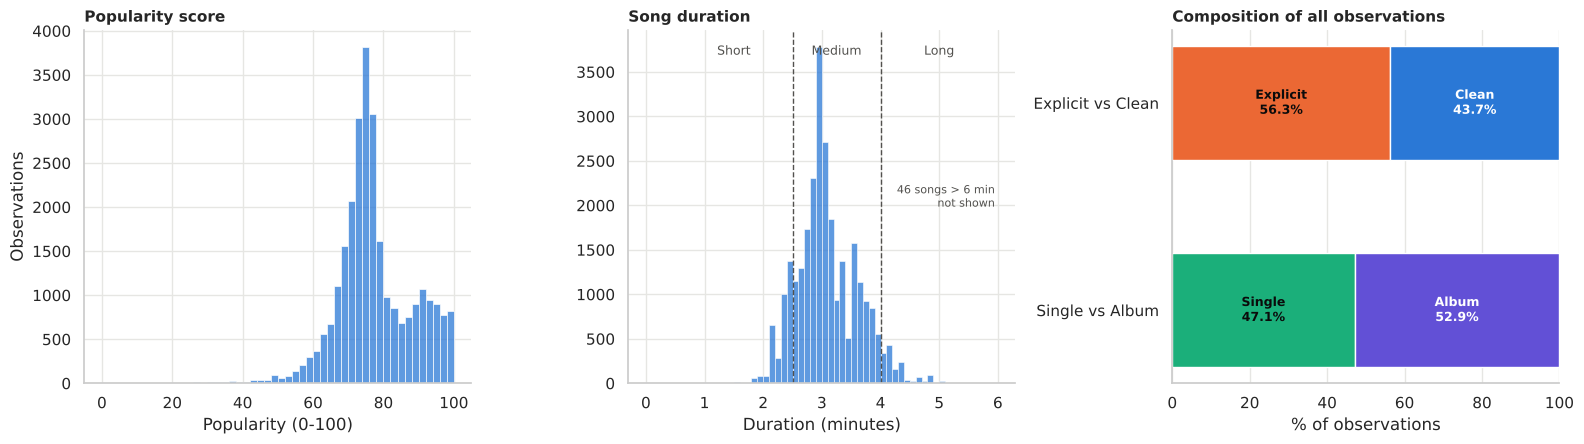

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) popularity
sns.histplot(df["popularity"].dropna(), bins=np.arange(0, 102, 2), color="#2a78d6", ax=axes[0])
axes[0].set(title="Popularity score", xlabel="Popularity (0-100)", ylabel="Observations")

# (b) duration with the group boundaries
dur = df["duration_min"].dropna()
sns.histplot(dur[dur <= 6], bins=np.arange(0, 6.1, 0.1), color="#2a78d6", ax=axes[1])
for edge in (dp.SHORT_MAX_MIN, dp.LONG_MIN_MIN):
    axes[1].axvline(edge, color="#52514e", ls="--", lw=1)
top = axes[1].get_ylim()[1]
for x, label in [(1.5, "Short"), (3.25, "Medium"), (5.0, "Long")]:
    axes[1].text(x, top * 0.93, label, ha="center", fontsize=9, color="#52514e")
axes[1].text(5.95, top * 0.5, f"{(dur > 6).sum()} songs > 6 min\nnot shown", ha="right", fontsize=8, color="#52514e")
axes[1].set(title="Song duration", xlabel="Duration (minutes)", ylabel="")

# (c) composition
rows = [("Explicit vs Clean", "explicit_category", ["Explicit", "Clean"]), ("Single vs Album", "release_format", ["Single", "Album"])]
for i, (label, col, cats) in enumerate(rows):
    left = 0
    for cat in cats:
        share = (df[col] == cat).mean() * 100
        axes[2].barh(i, share, left=left, color=COLORS[cat], edgecolor="white", height=0.55)
        axes[2].text(left + share / 2, i, f"{cat}\n{share:.1f}%", ha="center", va="center", color=TEXT_ON[cat], fontsize=9, fontweight="bold")
        left += share
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels([r[0] for r in rows]); axes[2].invert_yaxis()
axes[2].set(title="Composition of all observations", xlabel="% of observations", xlim=(0, 100))
fig.tight_layout()
save_fig(fig, "fig01_eda_overview")

**Interpretation.** The playlist holds 725 different songs by 324 artists across 555 days, so the same song appears on many days (on average 38.3 song-day rows per song). 56.3% of rows are explicit, 47.1% are singles, and the average song lasts 3.09 minutes. Popularity is concentrated between about 70 and 85 (mean 76.8, median 75.0). Because songs repeat across days, the 27,750 rows are **not** 27,750 independent observations - this matters for the statistics (section 15).

## 9. Explicit Content Analysis
Three things are kept apart: **representation** (how common), **popularity** (the popularity score) and **rank performance** (chart position). 'Top 10 rate' = % of the group's rows that are in positions 1-10 (20% would be proportional); 'lift' compares that with all rows.

In [9]:
explicit_profile = au.category_profile(df, "explicit_category", bounds)
explicit_bands = au.rank_band_distribution(df, "explicit_category")
explicit_tiers = au.tier_composition(df, "explicit_category")
explicit_monthly = au.explicit_over_time(df)
for name, table in [("04_explicit_profile", explicit_profile), ("05_explicit_rank_bands", explicit_bands),
                    ("06_explicit_tier_composition", explicit_tiers), ("07_explicit_monthly", explicit_monthly)]:
    save_table(table, name)
display(explicit_profile)
display(explicit_bands)
display(explicit_tiers)

,Category,Observations,Share (%),Unique tracks,Avg popularity,Median popularity,Avg position,Avg rank score,Top 10 rate (%),Top 25 rate (%),Top 10 lift (x),Content Acceptance Score
0,Explicit,15614,56.27,480,73.65,74.00,24.99,26.01,22.19,51.27,1.11,62.21
1,Clean,12136,43.73,250,80.93,81.00,26.16,24.84,17.18,48.37,0.86,64.70


,Category,Band 1-10 (%),Band 11-25 (%),Band 26-50 (%)
0,Explicit,22.19,29.08,48.73
1,Clean,17.18,31.19,51.63


,Category,Top 10,Top 25,Top 50
0,Explicit,62.43,57.69,56.27
1,Clean,37.57,42.31,43.73


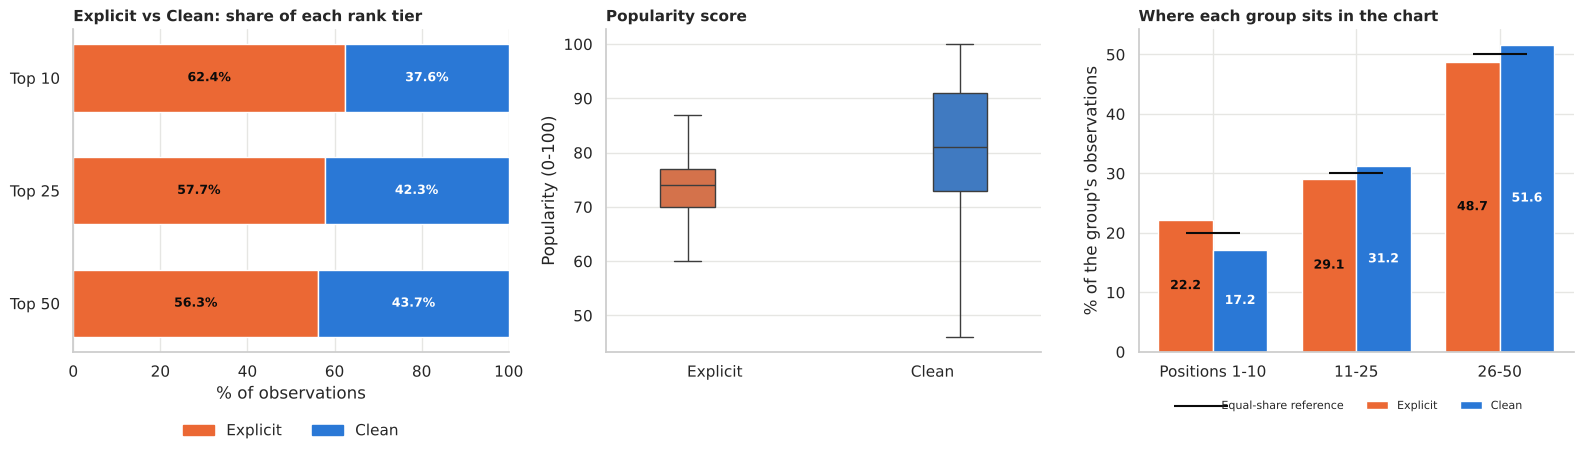

In [10]:
def group_overview(col, order, title, fig_name):
    """Three panels: (a) share of each rank tier, (b) popularity, (c) where each group sits in the chart."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

    # (a) composition of Top 10 / Top 25 / Top 50  (representation)
    comp = au.tier_composition(df, col).set_index("Category")
    for i, tier in enumerate(au.TIER_NAMES):
        left = 0
        for cat in order:
            share = comp.loc[cat, tier]
            axes[0].barh(i, share, left=left, color=COLORS[cat], edgecolor="white", height=0.6)
            axes[0].text(left + share / 2, i, f"{share:.1f}%", ha="center", va="center", color=TEXT_ON[cat], fontsize=9, fontweight="bold")
            left += share
    axes[0].set_yticks(range(3)); axes[0].set_yticklabels(au.TIER_NAMES); axes[0].invert_yaxis()
    axes[0].set(title=f"{title}: share of each rank tier", xlabel="% of observations", xlim=(0, 100))
    axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[c]) for c in order], labels=order,
                   loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)

    # (b) popularity
    sns.boxplot(data=df, x=col, y="popularity", order=order, hue=col, hue_order=order, palette=COLORS,
                legend=False, showfliers=False, width=0.5, ax=axes[1])
    axes[1].set(title="Popularity score", xlabel="", ylabel="Popularity (0-100)")

    # (c) rank bands vs what equal performance would look like
    bands = au.rank_band_distribution(df, col).set_index("Category")
    x = np.arange(3)
    width = 0.38
    for j, cat in enumerate(order):
        bars = axes[2].bar(x + (j - 0.5) * width, bands.loc[cat].values, width, color=COLORS[cat], label=cat)
        axes[2].bar_label(bars, fmt="%.1f", fontsize=9, label_type="center", color=TEXT_ON[cat], fontweight="bold")
    axes[2].scatter(x, [20, 30, 50], marker="_", s=1500, color="#0b0b0b", zorder=3, label="Equal-share reference")
    axes[2].set_xticks(x); axes[2].set_xticklabels(["Positions 1-10", "11-25", "26-50"])
    axes[2].set(title="Where each group sits in the chart", ylabel="% of the group's observations")
    axes[2].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
    fig.tight_layout()
    save_fig(fig, fig_name)

group_overview("explicit_category", ["Explicit", "Clean"], "Explicit vs Clean", "fig02_explicit_vs_clean")

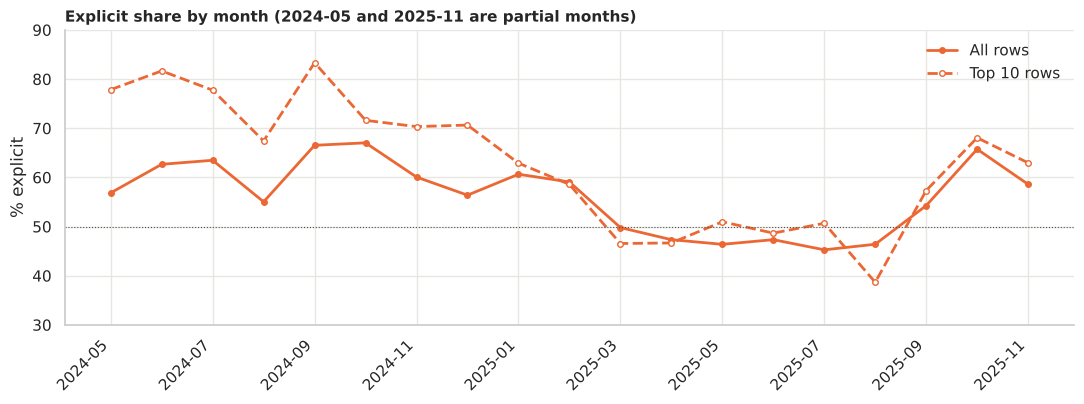

In [11]:
# Explicit share over time (first and last months are partial)
fig, ax = plt.subplots(figsize=(11, 4.2))
months = explicit_monthly["Month"]
ax.plot(months, explicit_monthly["Explicit share - all rows (%)"], color=COLORS["Explicit"], lw=2, marker="o", ms=4, label="All rows")
ax.plot(months, explicit_monthly["Explicit share - Top 10 (%)"], color=COLORS["Explicit"], lw=2, ls="--", marker="o", ms=4, mfc="white", label="Top 10 rows")
ax.axhline(50, color="#52514e", lw=0.8, ls=":")
ax.legend(frameon=False, loc="upper right")
ax.set_xticks(range(0, len(months), 2)); ax.set_xticklabels(months.iloc[::2], rotation=45, ha="right")
ax.set(title="Explicit share by month (2024-05 and 2025-11 are partial months)", ylabel="% explicit", ylim=(30, 90))
fig.tight_layout()
save_fig(fig, "fig03_explicit_share_over_time")

**Interpretation - three separate questions.**

- **Representation:** explicit rows are the majority (56.3% vs 43.7% clean; Clean Content Dominance Ratio = 0.78, i.e. clean is *not* dominant). Explicit also makes up 62.4% of the Top 10.
- **Popularity:** clean tracks score higher (mean 80.9 vs 73.6; median 81 vs 74).
- **Chart rank:** explicit tracks sit slightly higher (average position 25.0 vs 26.2; 22.2% of explicit rows are in the Top 10 vs 17.2% of clean rows).

So neither label wins on every measure. The explicit share is also not stable over time: it ranged from 45.3% (2025-07) to 67.0% (2024-10) across full months.

*Note: 'Unique tracks' in the profile table can add up to slightly more than the total because a few songs changed their explicit flag between days.*

## 10. Release Format Analysis
Singles vs Album tracks (the 9 'compilation' rows are counted as Album). Besides chart slots, the number of *distinct songs* and how long each stays on the chart are also compared, because a song can occupy many daily slots.

In [12]:
format_profile = au.category_profile(df, "release_format", bounds)
format_bands = au.rank_band_distribution(df, "release_format")
tracks = au.track_level(df)                                   # one row per unique song
format_tracks = tracks.groupby("release_format")["days_on_chart"].agg(
    unique_songs="size", avg_days_on_chart="mean", median_days_on_chart="median").reset_index()
save_table(format_profile, "08_format_profile")
save_table(format_bands, "09_format_rank_bands")
save_table(format_tracks, "10_format_track_level")
display(format_profile)
display(format_bands)
display(format_tracks)
print("Single-to-Album ratio (rows):", round(au.compute_kpis(df, bounds)["single_album_ratio"], 3))

,Category,Observations,Share (%),Unique tracks,Avg popularity,Median popularity,Avg position,Avg rank score,Top 10 rate (%),Top 25 rate (%),Top 10 lift (x),Content Acceptance Score
0,Single,13069,47.10,251,80.80,78.00,24.12,26.88,21.55,54.12,1.08,66.71
1,Album,14681,52.90,514,73.31,73.00,26.73,24.27,18.62,46.33,0.93,60.26


,Category,Band 1-10 (%),Band 11-25 (%),Band 26-50 (%)
0,Single,21.55,32.57,45.88
1,Album,18.62,27.72,53.67


,release_format,unique_songs,avg_days_on_chart,median_days_on_chart
0,Album,497,30.09,6.00
1,Single,228,56.13,21.50


Single-to-Album ratio (rows): 0.89


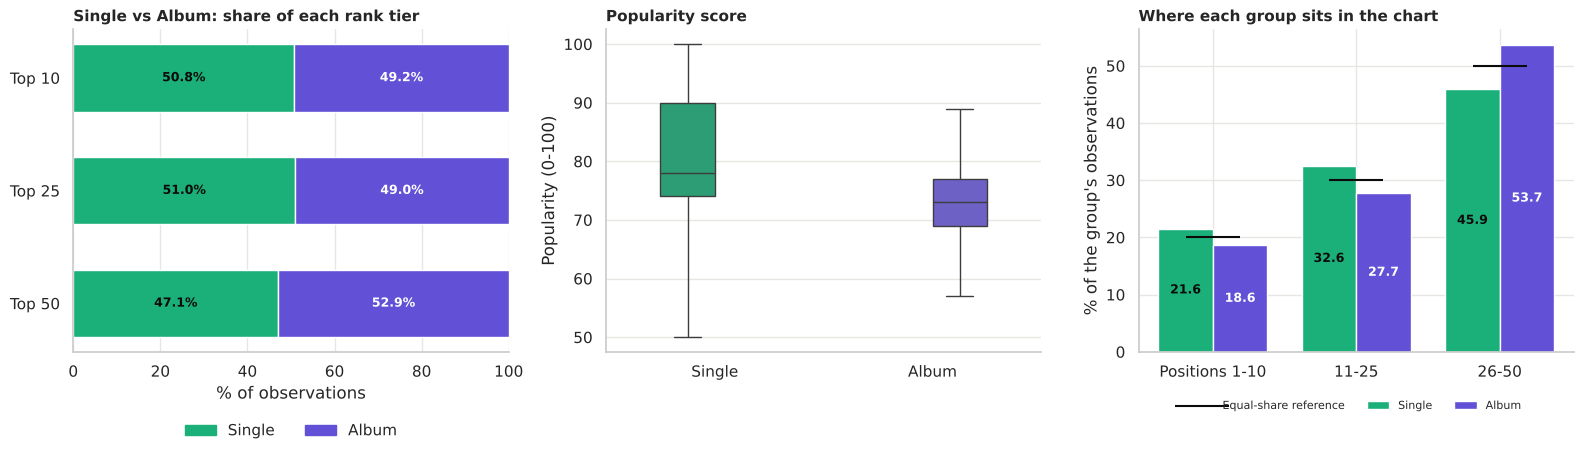

In [13]:
group_overview("release_format", ["Single", "Album"], "Single vs Album", "fig04_single_vs_album")

**Interpretation.** Album tracks hold a modest majority of chart slots (52.9% vs 47.1%; Single-to-Album ratio 0.89) and a clear majority of distinct songs (497 album-track songs vs 228 single songs, using each song's most frequent format). However, singles stay on the chart much longer per song (average 56.1 days vs 30.1) and perform better: higher popularity (80.8 vs 73.3), a better average position (24.1 vs 26.7) and a higher Top 10 rate (21.6% vs 18.6%). **Conclusion:** slightly stronger album-track *representation*, but stronger single *performance*.

## 11. Album Structure Analysis
Relationship between `total_tracks` (release size) and popularity, position, rank score and Top 10 presence. Size groups: Small 1-5, Medium 6-12, Large 13+. **Correlation does not prove causation.**

In [14]:
size_profile = au.category_profile(df, "album_size_group", bounds)
size_dist = au.album_size_distribution(df)
impact_all = au.album_size_impact(df)
impact_albums = au.album_size_impact(df[df["release_format"] == "Album"])   # check without 1-track singles
impact_table = pd.DataFrame([
    {"Data": "All observations", **impact_all},
    {"Data": "Album-type releases only", **impact_albums}])
save_table(size_profile, "11_album_size_group_profile")
save_table(size_dist, "12_album_size_distribution")
save_table(impact_table, "13_album_size_impact")
display(size_profile)
display(impact_table)
print(au.album_size_label(impact_all["index"]))

,Category,Observations,Share (%),Unique tracks,Avg popularity,Median popularity,Avg position,Avg rank score,Top 10 rate (%),Top 25 rate (%),Top 10 lift (x),Content Acceptance Score
0,Small (1-5),12536,45.17,242,81.06,79.00,24.01,26.99,21.97,54.35,1.10,66.95
1,Medium (6-12),4143,14.93,129,75.24,74.00,25.59,25.41,18.56,51.00,0.93,62.41
2,Large (13+),11071,39.90,397,72.65,73.00,27.15,23.85,18.31,44.70,0.92,59.50


,Data,rho_popularity,p_popularity,n_popularity,rho_rank_score,p_rank_score,n_rank_score,index
0,All observations,-0.35,0.00,27677,-0.11,0.00,27750,-0.23
1,Album-type releases only,-0.11,0.00,14617,-0.06,0.00,14681,-0.09


Small association: larger releases go with WEAKER track performance (dilution)


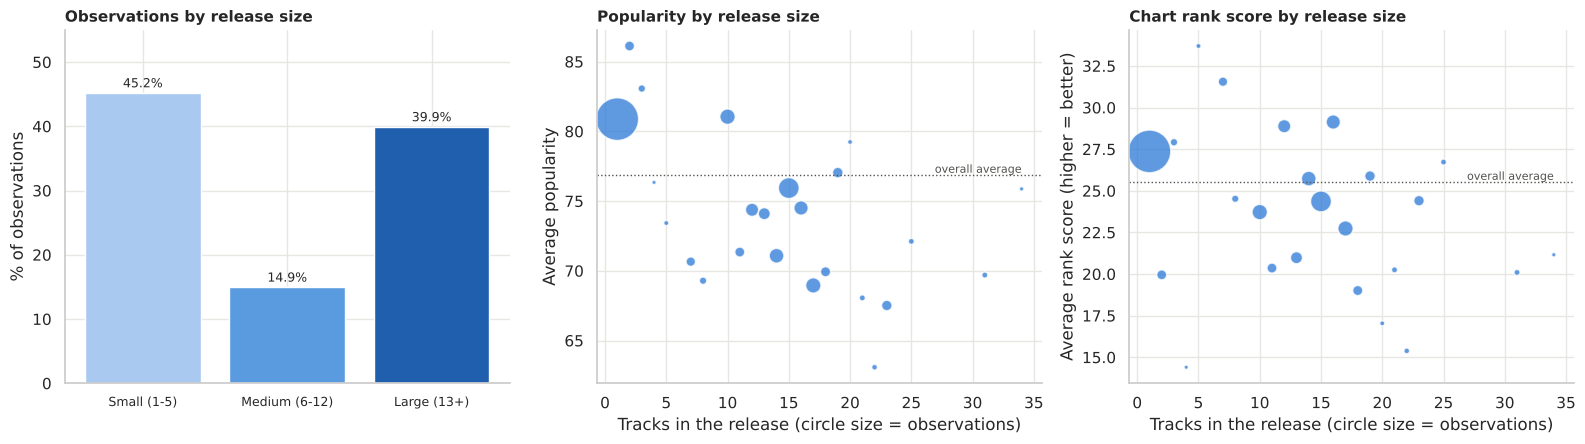

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) distribution by size group
dist = size_profile.set_index("Category")
bars = axes[0].bar(dist.index, dist["Share (%)"], color=SEQ, edgecolor="white")
axes[0].bar_label(bars, fmt="%.1f%%", fontsize=9, padding=2)
axes[0].set(title="Observations by release size", ylabel="% of observations", ylim=(0, 55))
axes[0].tick_params(axis="x", labelsize=9)

# (b) and (c): average by exact number of tracks (only sizes with at least 100 observations)
sizes = df.assign(total_tracks=df["total_tracks"].astype(float)).groupby("total_tracks").agg(
    n=("position", "size"), pop=("popularity", "mean"), rank_score=("rank_score", "mean")).reset_index()
sizes = sizes[sizes["n"] >= 100]
for ax, col, ylabel, ref in [(axes[1], "pop", "Average popularity", df["popularity"].mean()),
                             (axes[2], "rank_score", "Average rank score (higher = better)", df["rank_score"].mean())]:
    ax.scatter(sizes["total_tracks"], sizes[col], s=sizes["n"] / 12, color="#2a78d6", alpha=0.75, edgecolor="white", linewidth=1)
    ax.axhline(ref, color="#52514e", ls=":", lw=1)
    ax.text(sizes["total_tracks"].max(), ref, " overall average", va="bottom", ha="right", fontsize=8, color="#52514e")
    ax.set(xlabel="Tracks in the release (circle size = observations)", ylabel=ylabel)
axes[1].set_title("Popularity by release size")
axes[2].set_title("Chart rank score by release size")
fig.tight_layout()
save_fig(fig, "fig05_album_size")

**Interpretation.** Larger releases are associated with weaker per-track results: Spearman rho with popularity = -0.349, with rank score = -0.111; the Album Size Impact Index is **-0.230** (Small association: larger releases go with WEAKER track performance (dilution)). By size group, the Content Acceptance Score falls from 66.9 (Small) to 62.4 (Medium) and 59.5 (Large), and the Top 10 rate from 22.0% to 18.3%. **Important caveat:** the Small group is mostly singles (1-track releases), so much of this is the single-vs-album gap. Looking at album-type releases only, the index shrinks to -0.088 (popularity rho -0.111, rank-score rho -0.064) - a weak relationship. This is an association; it does not prove that a bigger album *causes* weaker tracks.

## 12. Duration Analysis
Duration statistics, the Short / Medium / Long split and 0.5-minute bands. 'Representation index' = a band's share of the **Top 10** divided by its share of **all rows** (above 1 = over-represented among the strongest positions).

In [16]:
dur_stats = au.duration_stats(df)
dur_group_profile = au.category_profile(df, "duration_group", bounds)
dur_bands = au.duration_band_table(df)
save_table(dur_stats, "14_duration_stats")
save_table(dur_group_profile, "15_duration_group_profile")
save_table(dur_bands, "16_duration_band_table")
display(dur_stats)
display(dur_group_profile)
display(dur_bands)

,Metric,Minutes
0,Mean,3.09
1,Median,3.00
2,Std. deviation,0.54
3,Minimum,0.67
4,Maximum,9.12
5,25th percentile,2.76
6,75th percentile,3.46


,Category,Observations,Share (%),Unique tracks,Avg popularity,Median popularity,Avg position,Avg rank score,Top 10 rate (%),Top 25 rate (%),Top 10 lift (x),Content Acceptance Score
0,Short,3576,12.89,103,77.20,74.00,26.12,24.88,17.73,48.77,0.89,62.85
1,Medium,22673,81.70,542,76.67,75.00,25.14,25.86,20.77,50.95,1.04,63.58
2,Long,1500,5.41,80,78.51,76.00,29.41,21.59,13.67,38.53,0.68,60.16


,Duration band (min),Observations,Share of all rows (%),Share of Top 10 (%),Top 10 rate (%),Representation index,Avg popularity,Avg rank score
0,<2.0,179,0.65,0.50,15.64,0.78,77.82,23.75
1,2.0-2.5,3397,12.24,10.92,17.84,0.89,77.17,24.94
2,2.5-3.0,10265,36.99,36.22,19.58,0.98,75.19,25.54
3,3.0-3.5,7381,26.60,29.25,21.99,1.10,76.98,25.67
4,3.5-4.0,5027,18.12,19.41,21.42,1.07,79.27,26.77
5,4.0-4.5,1200,4.32,2.92,13.50,0.68,80.54,21.30
6,4.5+,300,1.08,0.77,14.33,0.72,70.29,22.78


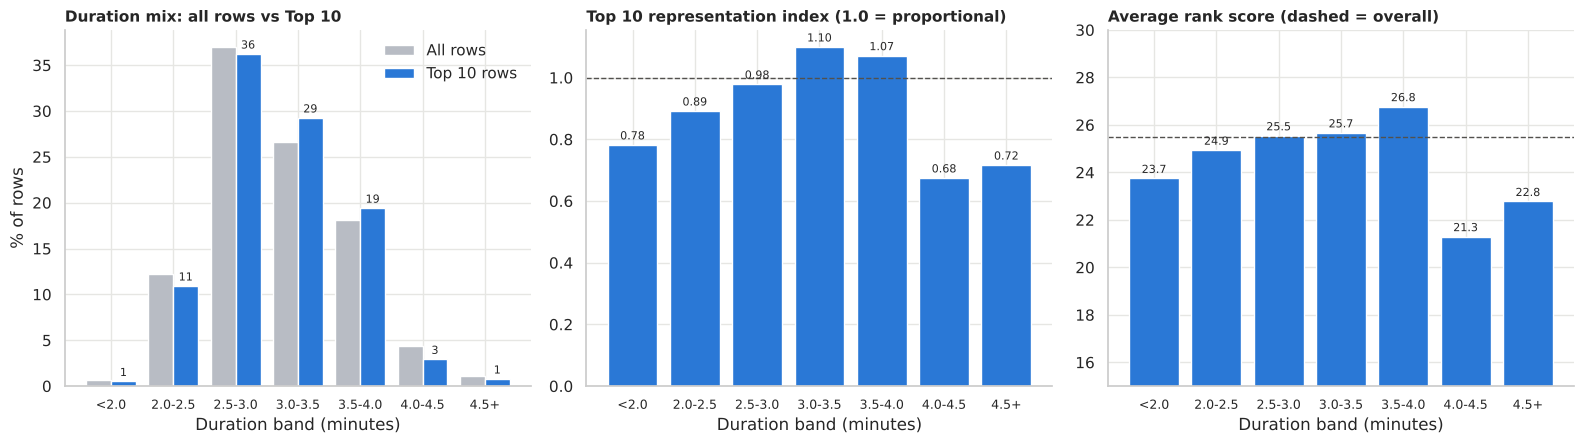

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
bands_idx = np.arange(len(dur_bands))
labels = dur_bands["Duration band (min)"].astype(str)

# (a) share of all rows vs share of the Top 10
w = 0.4
b1 = axes[0].bar(bands_idx - w / 2, dur_bands["Share of all rows (%)"], w, color=GREY, label="All rows")
b2 = axes[0].bar(bands_idx + w / 2, dur_bands["Share of Top 10 (%)"], w, color="#2a78d6", label="Top 10 rows")
axes[0].bar_label(b2, fmt="%.0f", fontsize=8, padding=2)
axes[0].set_xticks(bands_idx); axes[0].set_xticklabels(labels, fontsize=9)
axes[0].set(title="Duration mix: all rows vs Top 10", xlabel="Duration band (minutes)", ylabel="% of rows")
axes[0].legend(frameon=False)

# (b) representation index
bars = axes[1].bar(bands_idx, dur_bands["Representation index"], color="#2a78d6")
axes[1].axhline(1, color="#52514e", ls="--", lw=1)
axes[1].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
axes[1].set_xticks(bands_idx); axes[1].set_xticklabels(labels, fontsize=9)
axes[1].set(title="Top 10 representation index (1.0 = proportional)", xlabel="Duration band (minutes)")

# (c) average rank score
bars = axes[2].bar(bands_idx, dur_bands["Avg rank score"], color="#2a78d6")
axes[2].axhline(df["rank_score"].mean(), color="#52514e", ls="--", lw=1)
axes[2].bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
axes[2].set_xticks(bands_idx); axes[2].set_xticklabels(labels, fontsize=9)
axes[2].set(title="Average rank score (dashed = overall)", xlabel="Duration band (minutes)", ylim=(15, 30))
fig.tight_layout()
save_fig(fig, "fig06_duration")

**Interpretation.** Songs last 3.09 minutes on average (median 3.00, range 0.67-9.12). Medium songs (2.5-4 min) make up 81.7% of all rows and 84.9% of Top 10 rows; Long songs (> 4 min) are under-represented in the Top 10 (3.7% vs 5.4% overall). The largest single share of the Top 10 is the 2.5-3.0 min band (36.2%), while the bands most over-represented relative to their overall presence are 3.0-3.5 and 3.5-4.0 min (representation index 1.10 and 1.07). Duration has essentially no monotonic link with rank score (rho = -0.008), so the data supports a *preferred range* (about 2.5-4 minutes), not an exact ideal length.

*Bands with few observations (under 2.0 and 4.5+ minutes) are small, so read their values with care.*

## 13. Rank-Tier Analysis
How the Top 10, Top 25 and Top 50 differ. The tiers overlap (Top 10 is inside Top 25), so mutually exclusive **bands** (1-10, 11-25, 26-50) are shown as well.

In [18]:
tier_table = au.tier_summary(df)
band_table = au.band_summary(df)
save_table(tier_table, "17_rank_tier_summary")
save_table(band_table, "18_rank_band_summary")
display(tier_table)
display(band_table)

,Attribute,Top 10,Top 25,Top 50
0,Observations,5550,13875,27750
1,Explicit share (%),62.43,57.69,56.27
2,Clean share (%),37.57,42.31,43.73
3,Single share (%),50.76,50.98,47.10
4,Album-track share (%),49.24,49.02,52.90
5,Avg popularity,78.50,78.22,76.84
6,Avg duration (min),3.09,3.08,3.09
7,Short share (%),11.43,12.57,12.89
8,Medium share (%),84.88,83.26,81.71
9,Long share (%),3.69,4.17,5.41


,Attribute,1-10,11-25,26-50
0,Observations,5550,8325,13875
1,Explicit share (%),62.43,54.53,54.84
2,Clean share (%),37.57,45.47,45.16
3,Single share (%),50.76,51.12,43.21
4,Album-track share (%),49.24,48.88,56.79
5,Avg popularity,78.50,78.03,75.47
6,Avg duration (min),3.09,3.08,3.10
7,Short share (%),11.43,13.33,13.20
8,Medium share (%),84.88,82.19,80.15
9,Long share (%),3.69,4.48,6.65


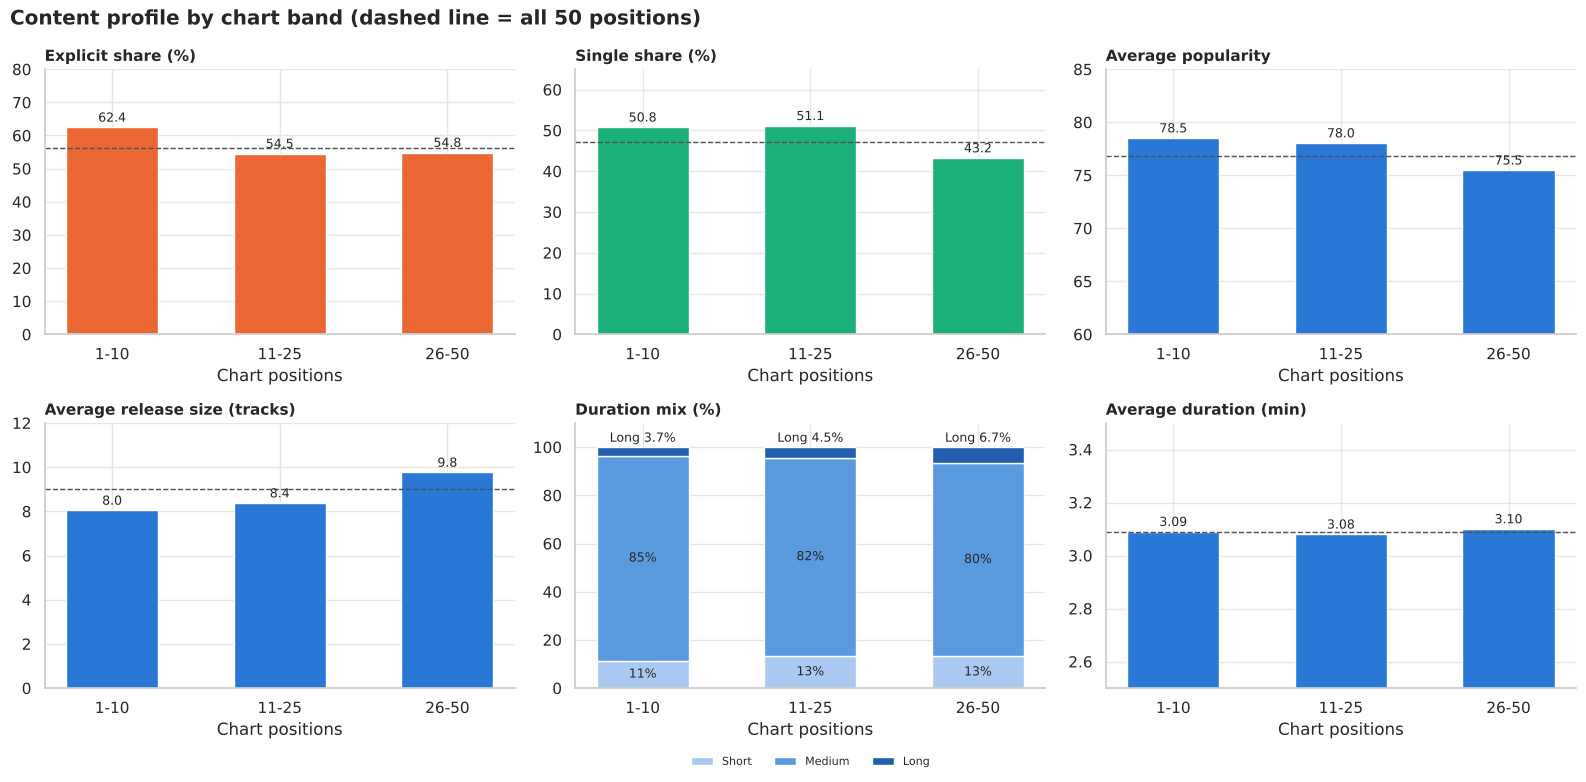

In [19]:
bt = band_table.set_index("Attribute")
band_names = list(bt.columns)
overall = au.tier_summary(df).set_index("Attribute")["Top 50"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

def simple_panel(ax, attribute, title, color, fmt="%.1f", ylim=None):
    bars = ax.bar(band_names, bt.loc[attribute].astype(float), color=color, width=0.55)
    ax.axhline(float(overall[attribute]), color="#52514e", ls="--", lw=1)
    ax.bar_label(bars, fmt=fmt, fontsize=9, padding=2)
    ax.set(title=title, xlabel="Chart positions")
    if ylim: ax.set_ylim(*ylim)

simple_panel(axes[0, 0], "Explicit share (%)", "Explicit share (%)", COLORS["Explicit"], ylim=(0, 80))
simple_panel(axes[0, 1], "Single share (%)", "Single share (%)", COLORS["Single"], ylim=(0, 65))
simple_panel(axes[0, 2], "Avg popularity", "Average popularity", "#2a78d6", ylim=(60, 85))
simple_panel(axes[1, 0], "Avg album size (tracks)", "Average release size (tracks)", "#2a78d6", ylim=(0, 12))
simple_panel(axes[1, 2], "Avg duration (min)", "Average duration (min)", "#2a78d6", fmt="%.2f", ylim=(2.5, 3.5))

# duration mix as 100% stacked bars (Long share is written above the bar because the segment is thin)
bottom = np.zeros(3)
for label, color in zip(["Short share (%)", "Medium share (%)", "Long share (%)"], SEQ):
    vals = bt.loc[label].astype(float).values
    axes[1, 1].bar(band_names, vals, bottom=bottom, color=color, edgecolor="white", width=0.55, label=label.split(" ")[0])
    for i, v in enumerate(vals):
        if label.startswith("Long"):
            axes[1, 1].text(i, 101, f"Long {v:.1f}%", ha="center", va="bottom", fontsize=9)
        else:
            axes[1, 1].text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=9)
    bottom += vals
axes[1, 1].set(title="Duration mix (%)", xlabel="Chart positions", ylim=(0, 110))
axes[1, 1].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8)
fig.suptitle("Content profile by chart band (dashed line = all 50 positions)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig07_rank_band_profile")

**Interpretation.** The Top 10 differs from the rest of the chart in a few ways: it is more explicit (62.4% in positions 1-10 vs 54.5% and 54.8% in the other bands), more single-heavy (50.8% vs 43.2% in positions 26-50), more popular (average 78.5 vs 75.5) and built from smaller releases (average 8.0 vs 9.8 tracks). Average duration is practically identical across bands (3.09 vs 3.10 min). Cumulative tiers (Top 10 inside Top 25 inside Top 50) are shown for reference; the mutually exclusive bands avoid double counting and give the cleaner comparison.

## 14. KPI Calculation
All required KPIs for the full dataset, and the Content Acceptance Score for each group. Formulas, interpretation and limitations of the two project-specific indices are given below the table.

In [20]:
kpis = au.kpi_table(df, bounds)
save_table(kpis, "19_kpi_summary")
display(kpis)

# Content Acceptance Score for each group
cas_tables = []
for label, table in [("Explicit vs Clean", explicit_profile), ("Single vs Album", format_profile),
                     ("Duration group", dur_group_profile), ("Album-size group", size_profile)]:
    part = table[["Category", "Observations", "Avg popularity", "Avg rank score", "Content Acceptance Score"]].copy()
    part.insert(0, "Comparison", label)
    cas_tables.append(part)
cas = pd.concat(cas_tables, ignore_index=True)
save_table(cas, "20_content_acceptance_scores")
display(cas)

,KPI,Value,Definition
0,Total observations,"27,750.00",Song-day rows (one row = one song on one date)
1,Explicit Content Share (%),56.27,Explicit rows / total rows x 100
2,Clean Content Dominance Ratio,0.78,Clean rows / Explicit rows
3,Single vs Album Track Ratio,0.89,Single rows / Album-track rows
4,Average Song Duration (min),3.09,"Mean of duration_ms / 60,000"
5,Average Popularity,76.84,Mean popularity (valid scores only)
6,Album Size Impact Index,-0.23,"Mean of Spearman rho(total_tracks, popularity) and rho(total_tracks, rank_score); -1 to +1"
7,Content Acceptance Score,63.30,100 x (0.5 x normalised popularity + 0.5 x normalised rank score)


,Comparison,Category,Observations,Avg popularity,Avg rank score,Content Acceptance Score
0,Explicit vs Clean,Explicit,15614,73.65,26.01,62.21
1,Explicit vs Clean,Clean,12136,80.93,24.84,64.70
2,Single vs Album,Single,13069,80.80,26.88,66.71
3,Single vs Album,Album,14681,73.31,24.27,60.26
4,Duration group,Short,3576,77.20,24.88,62.85
5,Duration group,Medium,22673,76.67,25.86,63.58
6,Duration group,Long,1500,78.51,21.59,60.16
7,Album-size group,Small (1-5),12536,81.06,26.99,66.95
8,Album-size group,Medium (6-12),4143,75.24,25.41,62.41
9,Album-size group,Large (13+),11071,72.65,23.85,59.50


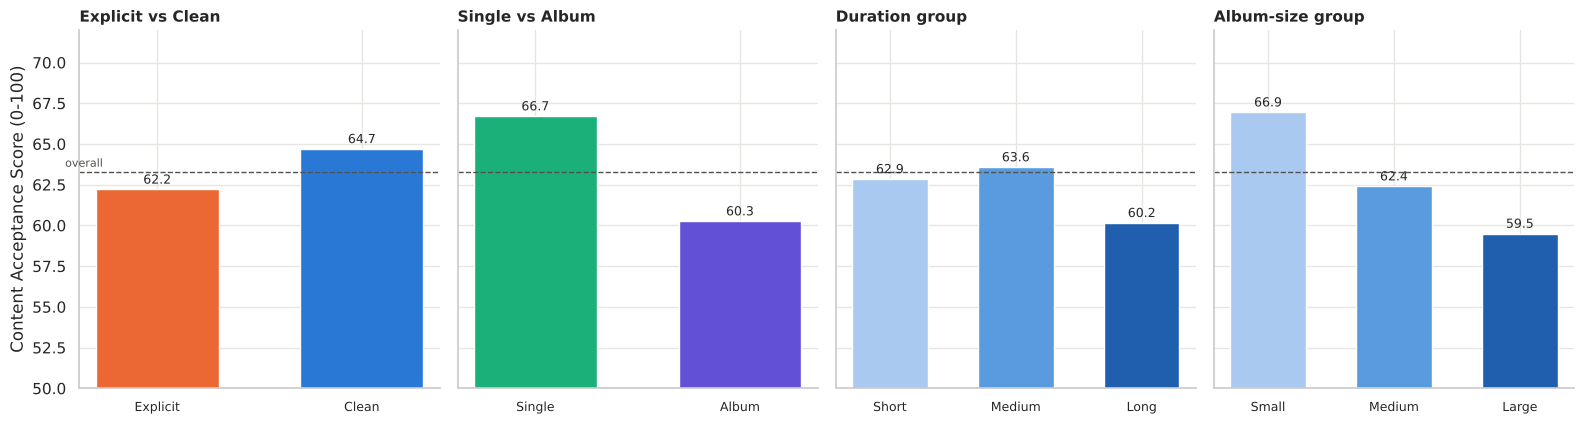

In [21]:
overall_cas = au.compute_kpis(df, bounds)["content_acceptance_score"]
groups = [("Explicit vs Clean", ["Explicit", "Clean"], [COLORS["Explicit"], COLORS["Clean"]]),
          ("Single vs Album", ["Single", "Album"], [COLORS["Single"], COLORS["Album"]]),
          ("Duration group", ["Short", "Medium", "Long"], SEQ),
          ("Album-size group", ["Small (1-5)", "Medium (6-12)", "Large (13+)"], SEQ)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
for ax, (label, cats, colors) in zip(axes, groups):
    vals = cas.set_index(["Comparison", "Category"]).loc[label].loc[cats, "Content Acceptance Score"]
    bars = ax.bar(range(len(cats)), vals, color=colors, width=0.6)
    ax.bar_label(bars, fmt="%.1f", fontsize=9, padding=2)
    ax.axhline(overall_cas, color="#52514e", ls="--", lw=1)
    ax.set_xticks(range(len(cats))); ax.set_xticklabels([c.split(" ")[0] for c in cats], fontsize=9)
    ax.set_title(label); ax.set_ylim(50, 72)
axes[0].set_ylabel("Content Acceptance Score (0-100)")
axes[0].text(-0.45, overall_cas + 0.3, "overall", fontsize=8, color="#52514e")
fig.tight_layout()
save_fig(fig, "fig08_content_acceptance_score")

**Interpretation.** Explicit content is 56.3% of rows; the Clean Content Dominance Ratio of 0.78 means there are fewer clean than explicit rows. The Single vs Album Track Ratio is 0.89. The average song lasts 3.09 minutes. The overall Content Acceptance Score is 63.3; it is a *relative* index, so compare groups with each other rather than reading 63 as 'good' or 'bad'. By group: Clean 64.7 vs Explicit 62.2; Single 66.7 vs Album 60.3; Medium duration 63.6 (best) vs Long 60.2; Small releases 66.9 vs Large 59.5. Clean scores above Explicit because of its higher popularity, even though explicit tracks hold slightly better chart positions - the score blends the two.

**Album Size Impact Index**

- *Formula:* `Index = (rho(total_tracks, popularity) + rho(total_tracks, rank_score)) / 2`, where rho is the Spearman rank correlation. Range -1 to +1.
- *Interpretation:* above 0 = bigger releases go with stronger tracks; below 0 = bigger releases go with weaker tracks ('dilution'); about 0 = no real relationship. Size labels follow the usual convention: |index| < 0.1 negligible, 0.1-0.3 small, 0.3-0.5 moderate, > 0.5 strong.
- *Limitations:* it is a correlation, not a cause; singles (1 track) dominate the low end, so it mixes 'single vs album' with 'album size' (see the albums-only check); popularity is a platform score, not streams; repeated daily rows of the same song are treated as separate observations.

**Content Acceptance Score** (project-specific index, *not* an industry metric)

- *Formula:* `CAS = 100 x (0.5 x Normalised Popularity + 0.5 x Normalised Rank Score)`, with Normalised Popularity = (mean popularity - 1) / (100 - 1) and Normalised Rank Score = (mean rank score - 1) / 49. The popularity minimum and maximum come from the full cleaned dataset, so scores stay comparable across filters.
- *Interpretation:* higher = the group is both more popular and higher on the chart. A group with average popularity and an average chart position scores about 63 here.
- *Limitations:* the 50/50 weighting is a modelling choice; the score has no significance test of its own; it inherits every limitation of popularity and rank.

## 15. Statistical Analysis
First check whether the data is normal (it is not), then use **Mann-Whitney U** for two-group comparisons and **Spearman** for relationships. Chart rank is tested through `rank_score` (higher = better). The *effect size* `r` (rank-biserial correlation) tells how large a difference is: below 0.1 negligible, 0.1-0.3 small, 0.3-0.5 moderate, above 0.5 strong. Each test is run twice: on **song-day rows** (as requested) and on **unique songs** (one row per song) as a robustness check, because the same song appears on many days.

In [22]:
normality = au.normality_check(df)
group_tests = au.run_group_tests(df)
corr_all = au.run_correlations(df)
corr_albums = au.run_correlations(df, album_only=True)
save_table(normality, "21_normality_check")
save_table(group_tests, "22_statistical_tests")
save_table(corr_all, "23_spearman_correlations")
save_table(corr_albums, "24_spearman_correlations_albums_only")

display(normality)
display(group_tests[["Level", "Question", "Test", "Test statistic (U)", "p-value (display)", "Effect size (r)", "n (group A / B)"]])
display(group_tests[["Level", "Statistical conclusion", "Business interpretation"]])

,Variable,Skewness,Normality test p-value,Conclusion
0,Popularity,-0.28,0.00,Not normal -> use Mann-Whitney U / Spearman
1,Rank score,0.00,0.00,Not normal -> use Mann-Whitney U / Spearman
2,Duration (min),0.85,0.00,Not normal -> use Mann-Whitney U / Spearman


,Level,Question,Test,Test statistic (U),p-value (display),Effect size (r),n (group A / B)
0,Observation (song-day),Is popularity different for Explicit vs Clean?,Mann-Whitney U,"57,450,697.50",< 0.001,-0.39,"15,546 / 12,131"
1,Observation (song-day),Is chart rank different for Explicit vs Clean? (rank score; higher = better),Mann-Whitney U,"99,158,557.00",< 0.001,0.05,"15,614 / 12,136"
2,Observation (song-day),Is popularity different for Single vs Album?,Mann-Whitney U,"134,251,970.00",< 0.001,0.41,"13,060 / 14,617"
3,Observation (song-day),Is chart rank different for Single vs Album? (rank score; higher = better),Mann-Whitney U,"105,950,467.00",< 0.001,0.10,"13,069 / 14,681"
4,Unique track (robustness),Is popularity different for Explicit vs Clean?,Mann-Whitney U,"29,071.00",< 0.001,-0.48,458 / 246
5,Unique track (robustness),Is chart rank different for Explicit vs Clean? (rank score; higher = better),Mann-Whitney U,"64,373.00",0.051,0.09,477 / 248
6,Unique track (robustness),Is popularity different for Single vs Album?,Mann-Whitney U,"70,752.50",< 0.001,0.31,225 / 479
7,Unique track (robustness),Is chart rank different for Single vs Album? (rank score; higher = better),Mann-Whitney U,"59,037.50",0.364,0.04,228 / 497


,Level,Statistical conclusion,Business interpretation
0,Observation (song-day),Significant difference (p < 0.001); effect size moderate (r = -0.39),Clean tracks tend to have higher popularity: median 74.0 (Explicit) vs 81.0 (Clean). The gap is moderate i...
1,Observation (song-day),Significant difference (p < 0.001); effect size negligible (r = +0.05),Explicit tracks tend to have a better (higher) rank score: median 26.0 (Explicit) vs 25.0 (Clean). The gap...
2,Observation (song-day),Significant difference (p < 0.001); effect size moderate (r = +0.41),Single tracks tend to have higher popularity: median 78.0 (Single) vs 73.0 (Album). The gap is moderate in...
3,Observation (song-day),Significant difference (p < 0.001); effect size small (r = +0.10),Single tracks tend to have a better (higher) rank score: median 27.0 (Single) vs 23.0 (Album). The gap is ...
4,Unique track (robustness),Significant difference (p < 0.001); effect size moderate (r = -0.48),Clean tracks tend to have higher popularity: median 65.7 (Explicit) vs 75.3 (Clean). The gap is moderate i...
5,Unique track (robustness),No significant difference (p = 0.051); effect size negligible (r = +0.09),No reliable difference between Explicit and Clean on rank score (medians 18.6 vs 15.9).
6,Unique track (robustness),Significant difference (p < 0.001); effect size moderate (r = +0.31),Single tracks tend to have higher popularity: median 73.1 (Single) vs 66.9 (Album). The gap is moderate in...
7,Unique track (robustness),No significant difference (p = 0.364); effect size negligible (r = +0.04),No reliable difference between Single and Album on rank score (medians 19.0 vs 17.3).


,Relationship,Spearman rho,p-value (display),n,Strength,Statistical conclusion
0,Popularity vs rank score,0.18,< 0.001,27677,small,Small positive monotonic relationship (p < 0.001)
1,Duration (min) vs popularity,0.10,< 0.001,27677,negligible,Negligible relationship (p < 0.001)
2,Duration (min) vs rank score,-0.01,0.195,27749,negligible,Negligible relationship (p 0.195)
3,Album size vs popularity,-0.35,< 0.001,27677,moderate,Moderate negative monotonic relationship (p < 0.001)
4,Album size vs rank score,-0.11,< 0.001,27750,small,Small negative monotonic relationship (p < 0.001)
5,Album size vs duration (min),0.12,< 0.001,27749,small,Small positive monotonic relationship (p < 0.001)


,Relationship,Spearman rho,p-value (display),n,Strength,Statistical conclusion
0,Popularity vs rank score,0.12,< 0.001,14617,small,Small positive monotonic relationship (p < 0.001)
1,Duration (min) vs popularity,0.20,< 0.001,14617,small,Small positive monotonic relationship (p < 0.001)
2,Duration (min) vs rank score,-0.06,< 0.001,14681,negligible,Negligible relationship (p < 0.001)
3,Album size vs popularity,-0.11,< 0.001,14617,small,Small negative monotonic relationship (p < 0.001)
4,Album size vs rank score,-0.06,< 0.001,14681,negligible,Negligible relationship (p < 0.001)
5,Album size vs duration (min),0.02,0.017,14681,negligible,Negligible relationship (p 0.017)


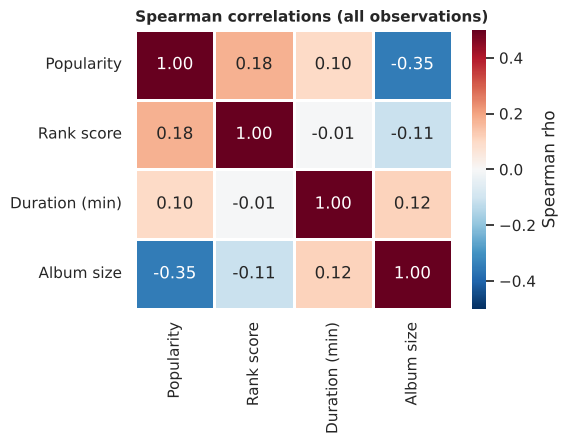

In [23]:
display(corr_all.drop(columns="p-value"))
display(corr_albums.drop(columns="p-value"))

# Heatmap of the main relationships
cols = {"popularity": "Popularity", "rank_score": "Rank score", "duration_min": "Duration (min)", "total_tracks": "Album size"}
matrix = df[list(cols)].astype(float).rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.8, 4.6))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, linewidths=2, linecolor="white",
            cbar_kws={"label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlations (all observations)")
fig.tight_layout()
save_fig(fig, "fig09_spearman_heatmap")

**Interpretation.** With ~27,750 rows almost any difference becomes 'statistically significant', so the **effect size (r)** matters more than the p-value, and because songs repeat day after day the row-level p-values are overstated. The unique-track rows are the more conservative check.

- **Explicit vs Clean popularity:** robust. Clean is higher at both levels (r = -0.39 rows, -0.48 tracks; negative = explicit lower).
- **Explicit vs Clean rank:** significant at row level but negligible (r = +0.05) and **not** significant at track level (p = 0.051). Treat as a slight, not robust, edge.
- **Single vs Album popularity:** robust. Singles are higher at both levels (r = +0.41 rows, +0.31 tracks).
- **Single vs Album rank:** small at row level (r = +0.10) and **not** significant at track level (p = 0.364). Modest, not robust.
- **Spearman:** album size vs popularity rho = -0.349 (moderate negative); album size vs rank score rho = -0.111 (small negative); duration vs rank score rho = -0.008 (negligible); popularity vs rank score rho = 0.179 (small positive).

*Correlation does not prove causation, and none of these tests measures streaming volume.*

## 16. Key Findings
Answers to the ten final questions (result, evidence, interpretation, recommendation).


### Q1. What percentage of observations are explicit?
- **Result:** 56.3% (15,614 of 27,750 rows); 43.7% are clean.
- **Evidence:** Clean Content Dominance Ratio = 0.78. Explicit share of the Top 10 = 62.4%. Across full calendar months the explicit share moved between 45.3% (2025-07) and 67.0% (2024-10).
- **Interpretation:** explicit tracks are a slim majority, but the share is not constant over time.
- **Recommendation:** do not treat explicit content as an obstacle to French Top 50 presence.

### Q2. Do Clean or Explicit tracks perform better?
- **Result:** neither wins on every measure. Clean is higher on **popularity**; explicit is slightly higher on **chart position**.
- **Evidence:** average popularity 80.9 (clean) vs 73.6 (explicit), robust at row and track level. Average position 25.0 (explicit) vs 26.2 (clean); Top 10 rate 22.2% vs 17.2%, but the rank effect is negligible (r = +0.05) and not significant at track level. Content Acceptance Score: Clean 64.7 vs Explicit 62.2.
- **Interpretation:** representation (explicit is more common), popularity (clean is higher) and rank (explicit marginally higher) point in different directions, so the data does not show one label to be 'preferred'.
- **Recommendation:** decide explicit vs clean on artistic and commercial grounds; consider a clean version as a low-cost complement, not a replacement.

### Q3. Are Singles or Album tracks more represented?
- **Result:** slightly more album tracks - 52.9% of rows vs 47.1% singles.
- **Evidence:** Single-to-Album ratio 0.89; 497 album-track songs vs 228 single songs (68.6% album); but singles last longer on the chart per song (56.1 vs 30.1 days).
- **Interpretation:** a modest album-track edge in chart slots, not a strong one; singles are present for fewer songs but for longer.
- **Recommendation:** do not assume the French chart is a singles-only market; both routes reach the Top 50.

### Q4. Which release format performs better?
- **Result:** Singles.
- **Evidence:** average popularity 80.8 vs 73.3 (robust at both levels, r = +0.41 rows / +0.31 tracks); average position 24.1 vs 26.7; Top 10 rate 21.6% vs 18.6%; Content Acceptance Score 66.7 vs 60.3.
- **Interpretation:** the popularity advantage is solid; the rank advantage is modest and not significant at track level (p = 0.364).
- **Recommendation:** lead with singles or focus tracks when the goal is popularity and Top 10 entry.

### Q5. Which duration range is most represented among stronger tracks?
- **Result:** 2.5-4.0 minutes (Medium).
- **Evidence:** 84.9% of Top 10 rows are Medium vs 81.7% overall; Long songs are 3.7% of the Top 10 vs 5.4% overall. Largest single band in the Top 10: 2.5-3.0 min (36.2%); most over-represented: 3.0-3.5 and 3.5-4.0 min.
- **Interpretation:** a preferred range, not an exact ideal; duration is practically unrelated to rank score (rho = -0.008).
- **Recommendation:** aim for roughly 2.5-4 minutes; avoid assuming longer tracks help.

### Q6. Do larger albums help or weaken individual track performance?
- **Result:** larger releases are associated with *weaker* per-track results (Album Size Impact Index -0.230), mostly because singles do well.
- **Evidence:** Content Acceptance Score Small 66.9 > Medium 62.4 > Large 59.5. Within album-type releases only, the index is -0.088 (weak).
- **Interpretation:** a dilution-like pattern exists but is modest once singles are set aside; correlation does not prove causation.
- **Recommendation:** for album projects, concentrate promotion on a few focus tracks.

### Q7. Which attributes are concentrated in the Top 10?
- **Result:** explicit content, singles, higher popularity and smaller releases.
- **Evidence:** explicit 62.4% (vs 56.3% overall); singles 50.8% (vs 47.1%); average popularity 78.5 (vs 76.8); average album size 8.0 tracks (vs 9.0); Medium duration 84.9% (vs 81.7%). Average duration is the same (3.09 min).
- **Interpretation:** the Top 10 leans explicit, single-led and medium-length, but the differences are moderate rather than dramatic.
- **Recommendation:** use these as pitching guidelines, not rules.

### Q8. What is the observed preferred content profile?
- **Result:** a medium-length (2.5-4 min) track from a small release (single or up to 5 tracks). The explicit/clean label does not separate winners clearly.
- **Evidence:** highest Content Acceptance Scores - Medium duration 63.6, Single 66.7, Small release 66.9. For explicit vs clean the score favours Clean (64.7 vs 62.2) because of popularity, while explicit leads on Top 10 presence. The average Top 10 row is 62.4% explicit, 50.8% single, 84.9% medium length.
- **Interpretation:** descriptive only; the data shows what charts, not why.
- **Recommendation:** use as a starting profile for France-specific releases.

### Q9. What should Atlantic Recording Corporation consider for France-specific releases?
- **Result:** keep explicit content available, lead with singles, target 2.5-4 minutes, and keep album promotion focused.
- **Evidence:** see Q1-Q8. This dataset covers only the France playlist, so it cannot show what is *different* about France.
- **Interpretation:** the points above describe French chart behaviour; whether they differ from other markets needs a side-by-side comparison with other countries' playlists.
- **Recommendation:** run the same analysis on other markets' Top 50 data, and add genre, language and streaming data before finalising localisation decisions.

### Q10. What conclusions cannot be made from this dataset?
- **Result:** several tempting conclusions are not supported.
- **Evidence and limits:**
  - *Causation* - explicit content, format, length or album size cause chart success. Only associations are measured.
  - *Audience preference or regulation* - the data has no listener, demographic, skip-rate, streaming-volume or legal/regulatory information; the 'compliance' angle here is only the explicit flag.
  - *Streaming volume* - rank and popularity are not play counts.
  - *Genre or language effects* - not in the data. For example, the higher popularity of clean tracks may reflect which songs are clean, not the label itself.
  - *Stability over time* - the explicit share swings by more than 20 percentage points between months.
  - *Independent observations* - the same song appears on many days, which inflates significance.
- **Recommendation:** treat findings as a French-chart baseline and collect the missing data listed in the report.

## 17. Recommendations

### High confidence (strongly supported by the data)
- **Explicit-content strategy:** Do not remove or soften explicit content to qualify for the French Top 50. *Evidence:* 56.3% of rows and 62.4% of the Top 10 are explicit; explicit Top 10 rate 22.2% vs 17.2% clean.
- **Song duration:** Aim for roughly 2.5-4 minutes; treat tracks over 4 minutes as a risk to Top 10 presence. *Evidence:* Medium = 84.9% of Top 10 vs 81.7% overall; Long = 3.7% vs 5.4%.
- **Single vs Album release strategy:** Lead with singles or clear focus tracks when popularity and Top 10 entry are the goal; albums remain viable. *Evidence:* Singles: popularity 80.8 vs 73.3 (robust at track level); rank advantage modest and not robust.

### Moderate confidence (patterns present, more evidence needed)
- **Availability of clean versions:** Keep a clean version available as a low-cost complement to an explicit release. *Evidence:* Clean rows have higher popularity (80.9 vs 73.6) but not better chart positions; the data cannot show whether adding a clean version helps the same song.
- **Playlist pitching:** Pitch both explicit and clean material; emphasise single-led, medium-length tracks for the top positions. *Evidence:* Top 10 is 50.8% single and 84.9% medium length; differences are moderate.
- **Album structure:** For album projects, concentrate promotion on a few focus tracks rather than the whole tracklist. *Evidence:* Album Size Impact Index -0.230 overall, -0.088 within albums only (weak); correlation, not causation.

### Further data needed
- **France-specific localisation:** Use this analysis as the French baseline and compare it with other markets before localising. *Reason:* Only the France playlist is analysed; genre, language and artist origin are not in the data.

| Data needed | Why it matters |
|---|---|
| Streaming counts | Rank and popularity are not volumes; counts would show real consumption. |
| Skip rate and completion rate | Would show whether long or explicit tracks lose listeners. |
| Genre and language | Likely confounds explicit status, duration and popularity. |
| Listener demographics | Needed to speak about audience sensitivity or acceptance. |
| Marketing spend | Chart success may reflect promotion, not content. |
| Release timing | Release day and season affect chart entry. |
| Artist-level popularity | A few very popular artists may drive results. |
| Other markets' playlists | Needed to say what is specific to France. |

*Single vs Album is rated High for popularity and Moderate for chart rank (see the statistical analysis).*

## 18. Conclusion

In the France Top 50 (**555 daily snapshots, 2024-05-18 to 2025-11-27**), explicit content is the slight majority (56.3% of rows) and is over-represented in the Top 10 (62.4%), while clean tracks carry higher popularity scores - so the explicit/clean label does not decide success on its own. Album tracks fill slightly more chart slots (52.9%), but singles perform better, especially on popularity. The strongest tracks are mostly 2.5-4 minutes long, and larger releases show weaker per-track results, though this is modest once singles are set aside.

These are **associations in one playlist**, not causal effects. Streaming volume, genre, language, audience demographics and promotion are not in the data, so the findings should be treated as a French-chart baseline to be extended with the data listed in the recommendations.